<a href="https://colab.research.google.com/github/wonhoyeo-oss/CV2026/blob/main/homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [104]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from sklearn.datasets import make_blobs
from sklearn.datasets import make_moons
from matplotlib import pyplot
import pandas as pd
from pandas import DataFrame
import matplotlib.pyplot as plt

In [105]:
# random seed for always same results
tf.random.set_seed(678)
print(tf.__version__)

2.21.0


### model

In [106]:
model = Sequential()
# first dense layer
model.add(Dense(units=2, input_shape=(2,), activation='sigmoid'))
#model.add(Dense(units=4, activation='sigmoid'))
#model.add(Dense(units=4, activation='sigmoid'))
#model.add(Dense(units=2, activation='sigmoid'))
model.add(Dense(units=1, activation='sigmoid'))
# loss function and optimization

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [107]:
model.compile(tf.keras.optimizers.SGD(learning_rate=0.2), loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

### Simple Data Xy

In [108]:
X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y = np.array([0.,1.,1.,1.])

In [109]:
# generate 2d classification dataset
X, y = make_moons(n_samples=50, noise=.06)

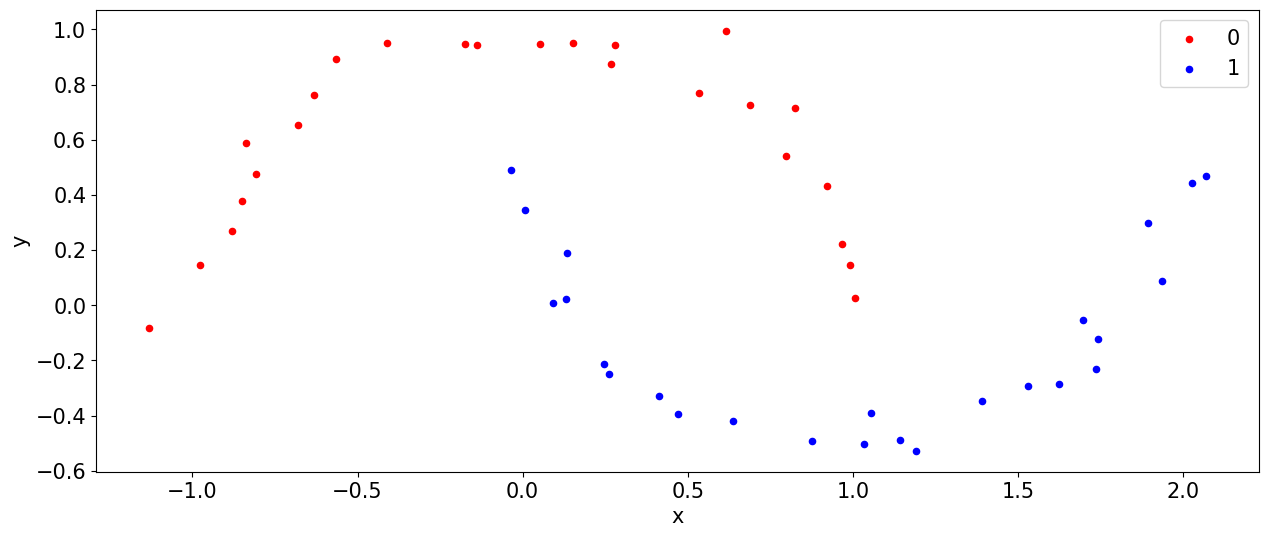

In [110]:
# scatter plot, dots colored by class value
df = DataFrame(dict(x=X[:,0], y=X[:,1], label=y))
colors = {0:'red', 1:'blue', 2:'green'}
fig, ax = pyplot.subplots()
grouped = df.groupby('label')
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
pyplot.show()

### model.fit

In [111]:
class callback(tf.keras.callbacks.Callback):
    SHOW_NUMBER = 1000
    counter = 0
    epoch = 0

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch = epoch

    def on_train_batch_end(self, batch, logs=None):
        if self.counter == self.SHOW_NUMBER or self.epoch == 1:
            print('Epoch: ' + str(self.epoch) + ' loss: ' + str(logs['loss']))
            if self.epoch > 1:
                self.counter = 0
        self.counter += 1

In [112]:
batchNum = 100
epochNum = 5000

In [113]:
history = model.fit(X, y, batch_size=batchNum, epochs=epochNum, callbacks=[callback()], verbose=0)

Epoch: 1 loss: 0.6026121377944946
Epoch: 1000 loss: 0.2803489565849304
Epoch: 2000 loss: 0.2778432369232178
Epoch: 3000 loss: 0.2763252556324005
Epoch: 4000 loss: 0.27525854110717773


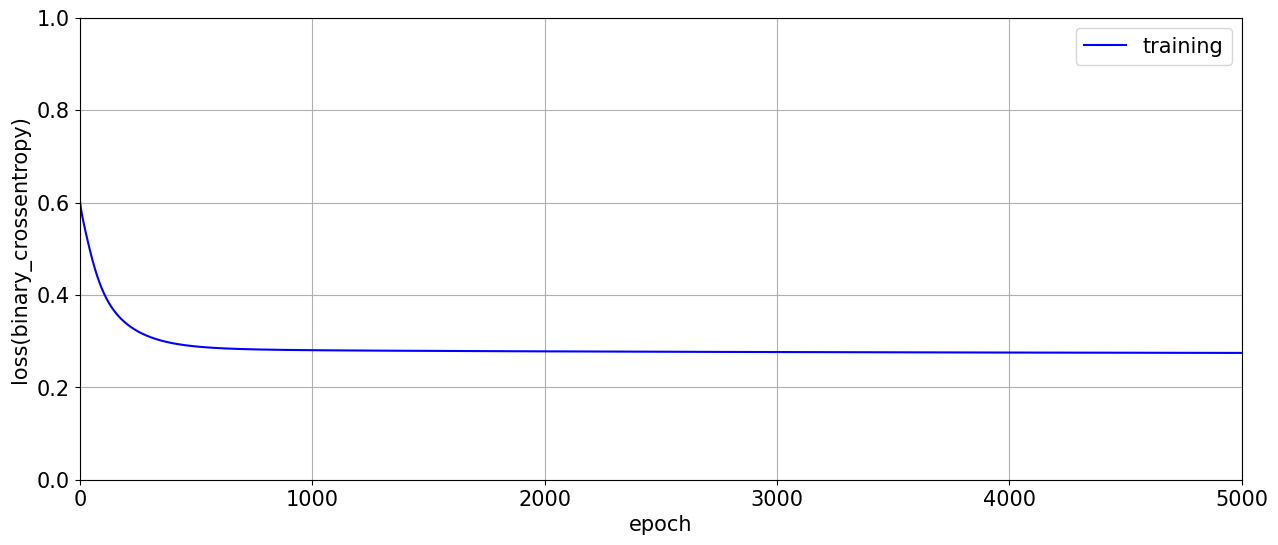

In [114]:
plt.plot(pd.DataFrame(history.history)[['loss']],'b', label='training')
# plt.figure(figsize=(5,5), dpi=10000, facecolor='w', edgecolor='k')
plt.xlabel("epoch")
plt.ylabel("loss(binary_crossentropy)")  # "Loss(MAE)"  logcosh
plt.rcParams['figure.figsize'] = [15, 6]
font = {'weight' : 'normal', 'size' : 15}
plt.rc('font', **font)
# plt.title('node #:' + str(nodeNum)+' / layer #:'+str(layerNum))
plt.grid(True)
plt.legend()
plt.xlim(-1, epochNum+1)
plt.ylim(0, 1)
# plt.savefig(MODEL_SAVE_FOLDER_PATH+'_learningcurve_'+case_name+'.png', dpi=300)
plt.show()

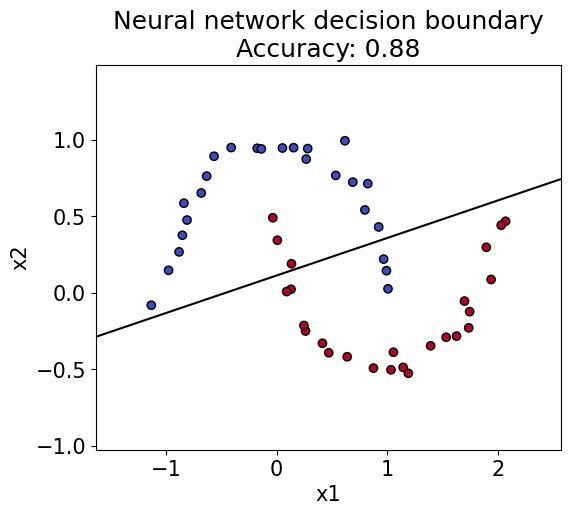

In [115]:
# 결정 경계 그래프: 기존 model, X, y를 그대로 사용
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0).reshape(xx.shape)

acc = np.mean((model.predict(X, verbose=0) > 0.5).astype(int).flatten() == y)

plt.figure(figsize=(6, 5))
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.5)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k')
plt.title(f"Neural network decision boundary\nAccuracy: {acc:.2f}")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

In [116]:
print("first layer weights: ",model.layers[0].get_weights()[0])
print("first layer bias: ",model.layers[0].get_weights()[1])
print("second layer weights: ",model.layers[1].get_weights()[0])
print("second layer bias: ",model.layers[1].get_weights()[1])

first layer weights:  [[ 0.52 -0.53]
 [-2.14  2.12]]
first layer bias:  [ 0.08 -0.31]
second layer weights:  [[ 5.68]
 [-5.  ]]
second layer bias:  [-0.19]


In [117]:
py = model.predict(X)
lpy = tf.cast(py > 0.5, dtype=tf.float32)
for i in range(0, len(py), 1):
  print(y[i], py[i], lpy.numpy()[i])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
0 [0.03] [0.]
1 [0.98] [1.]
1 [0.7] [1.]
1 [0.98] [1.]
0 [0.02] [0.]
1 [0.98] [1.]
0 [0.02] [0.]
1 [0.98] [1.]
1 [0.97] [1.]
0 [0.03] [0.]
0 [0.03] [0.]
0 [0.02] [0.]
1 [0.93] [1.]
1 [0.95] [1.]
1 [0.44] [0.]
0 [0.07] [0.]
0 [0.03] [0.]
1 [0.67] [1.]
1 [0.97] [1.]
1 [0.94] [1.]
0 [0.38] [0.]
0 [0.12] [0.]
0 [0.04] [0.]
1 [0.22] [0.]
0 [0.18] [0.]
0 [0.77] [1.]
1 [0.98] [1.]
0 [0.04] [0.]
0 [0.06] [0.]
0 [0.37] [0.]
1 [0.67] [1.]
1 [0.98] [1.]
0 [0.09] [0.]
0 [0.02] [0.]
0 [0.22] [0.]
0 [0.86] [1.]
0 [0.02] [0.]
1 [0.96] [1.]
1 [0.72] [1.]
1 [0.98] [1.]
1 [0.11] [0.]
1 [0.91] [1.]
0 [0.68] [1.]
1 [0.97] [1.]
1 [0.83] [1.]
0 [0.03] [0.]
0 [0.08] [0.]
1 [0.96] [1.]
0 [0.11] [0.]
1 [0.89] [1.]


In [118]:
model.weights

[<Variable path=sequential_4/dense_8/kernel, shape=(2, 2), dtype=float32, value=[[ 0.52 -0.53]
  [-2.14  2.12]]>,
 <Variable path=sequential_4/dense_8/bias, shape=(2,), dtype=float32, value=[ 0.08 -0.31]>,
 <Variable path=sequential_4/dense_9/kernel, shape=(2, 1), dtype=float32, value=[[ 5.68]
  [-5.  ]]>,
 <Variable path=sequential_4/dense_9/bias, shape=(1,), dtype=float32, value=[-0.19]>]

In [119]:
lpy = np.array(lpy)
print(lpy)

[[0.]
 [1.]
 [1.]
 [1.]
 [0.]
 [1.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [1.]
 [1.]
 [1.]
 [0.]
 [1.]
 [1.]
 [1.]
 [1.]
 [0.]
 [0.]
 [1.]
 [0.]
 [1.]]


In [120]:
lpy = np.reshape(lpy, (len(y),))
print(y.shape, lpy.shape)

(50,) (50,)


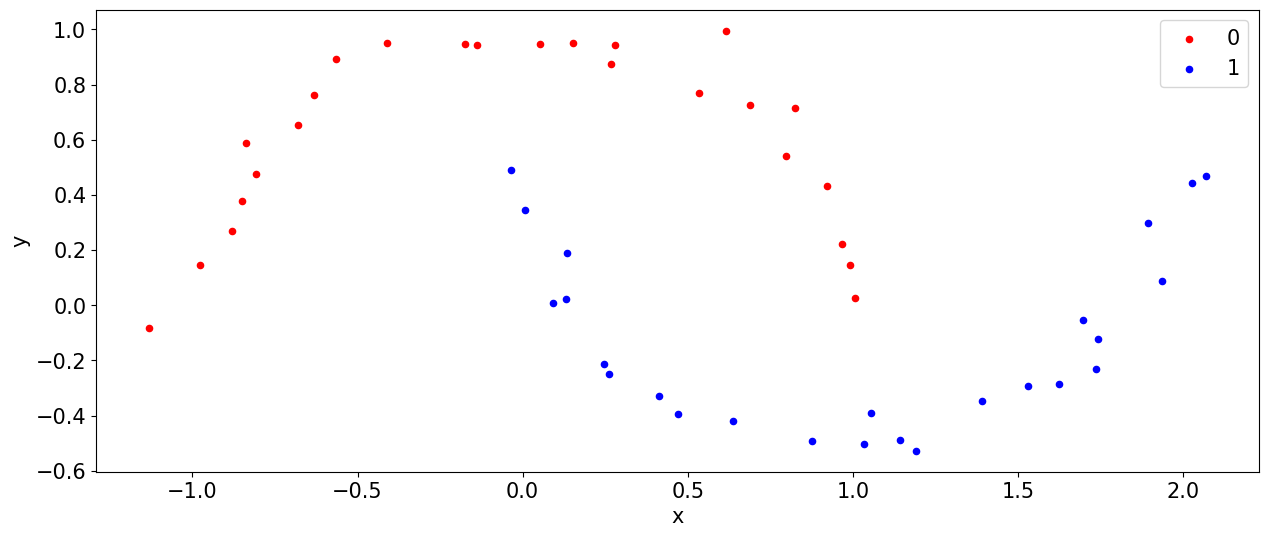

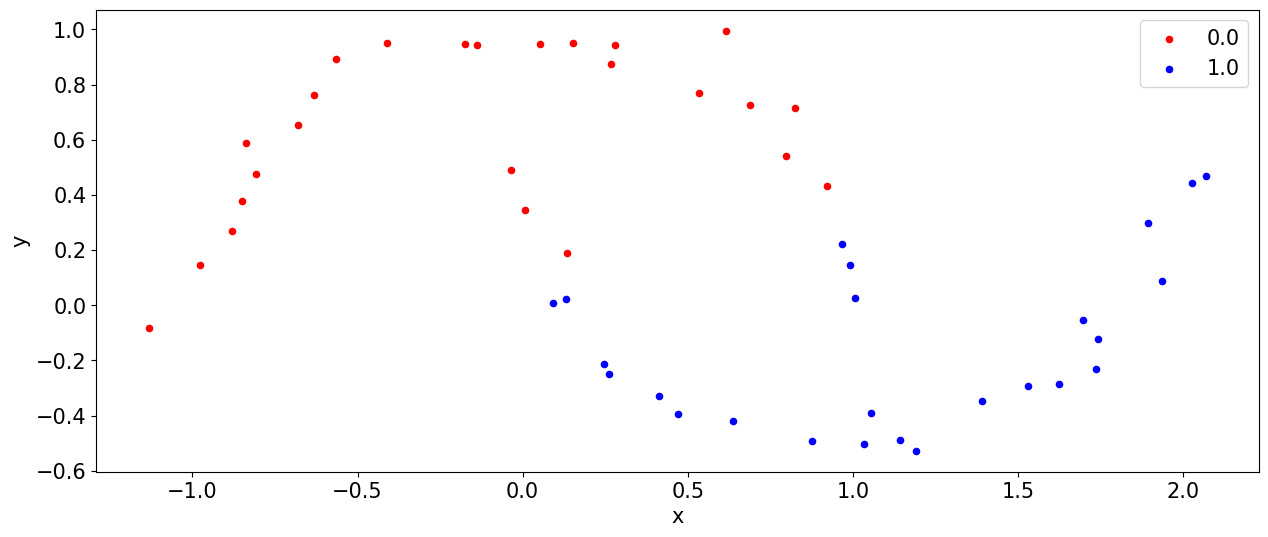

In [121]:
colors = {0:'red', 1:'blue'}

df = DataFrame(dict(x=X[:,0], y=X[:,1], label=y))
grouped = df.groupby('label')
fig, ax = pyplot.subplots()
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
pyplot.show()

df = DataFrame(dict(x=X[:,0], y=X[:,1], label=lpy))
grouped = df.groupby('label')
fig, ax = pyplot.subplots()
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
pyplot.show()

# generate blobs of points with a Gaussian distribution.

In [122]:
# generate 2d classification dataset
X, y = make_blobs(n_samples=100, centers=2, n_features=2)

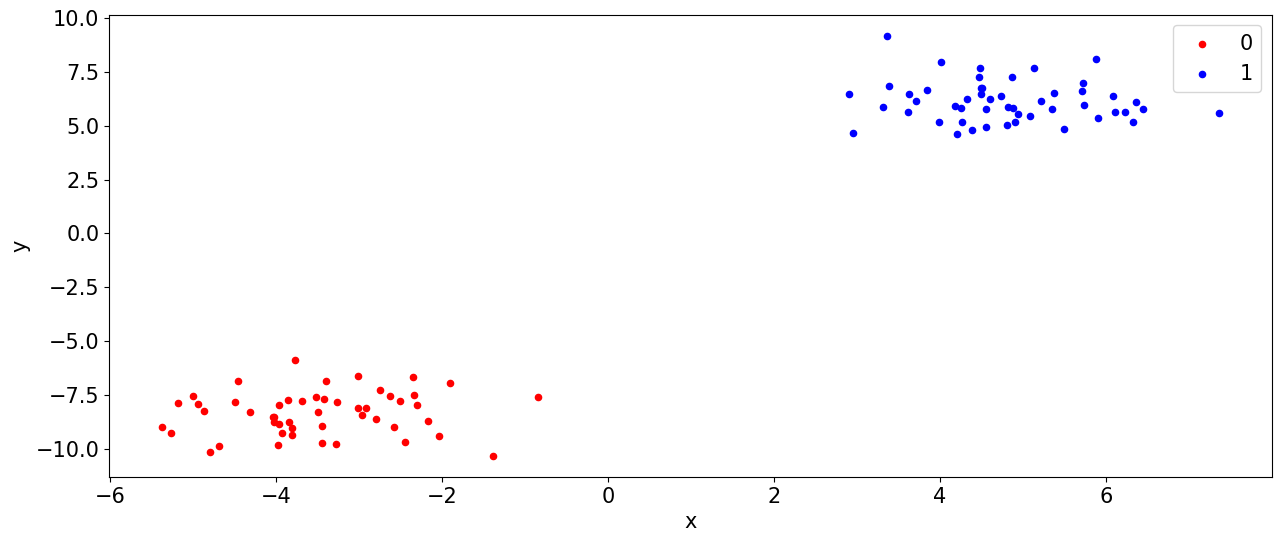

In [123]:
# scatter plot, dots colored by class value
df = DataFrame(dict(x=X[:,0], y=X[:,1], label=y))
colors = {0:'red', 1:'blue', 2:'green'}
fig, ax = pyplot.subplots()
grouped = df.groupby('label')
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
pyplot.show()

In [124]:
np.set_printoptions(linewidth=220, precision=2)
print(X.T)

[[  2.9    6.33   5.73   4.51  -3.81  -2.04  -4.5   -3.86  -5.27   4.18  -1.39   3.71  -4.05   4.9    3.85  -5.    -2.75   4.47   5.49  -4.69   6.23   6.45   4.6    5.87   4.21  -3.4   -3.01   4.5    4.49  -4.8   -2.97
    7.36  -0.85   6.36  -4.32   4.27  -2.45   5.71  -5.19   4.94  -3.97  -2.35   6.09   4.26  -3.85   3.62  -3.01  -3.81   5.08  -2.8   -4.47  -3.27   4.55  -3.29   4.02  -3.69  -2.51   6.11   4.55  -2.62   3.31  -3.94
   -1.9   -3.78  -4.03   3.61  -2.34  -2.58  -3.97   3.36  -3.45   2.95   5.37   4.8   -3.52   5.22  -3.5   -3.42   4.73   4.88   5.72   4.82   3.98  -2.93   5.14  -2.3   -4.87   4.48   5.9   -3.44   5.35  -5.38  -4.03
    4.87  -3.98  -2.17   4.39   4.33   3.39  -4.95]
 [  6.48   5.17   5.97   6.77  -9.03  -9.38  -7.83  -7.74  -9.26   5.93 -10.32   6.13  -8.51   5.17   6.68  -7.54  -7.25   7.25   4.85  -9.85   5.61   5.78   6.25   8.09   4.59  -6.85  -6.64   6.73   6.46 -10.14  -8.42
    5.61  -7.59   6.08  -8.31   5.18  -9.69   6.61  -7.87   5.52  -8.83 

In [125]:
print(y)

[1 1 1 1 0 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 1 1 1 1 1 0 0 1 1 0 0 1 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0 0 1 0 0 0 1 0 1 0 0 1 1 0 1 0 0 0 0 1 0 0 0 1 0 1 1 1 0 1 0 0 1 1 1 1 1 0 1 0 0 1 1 0 1 0 0 1 0 0 1 1 1 0]


In [126]:
# generate 2d classification dataset
X, y = make_moons(n_samples=100, noise=.16)

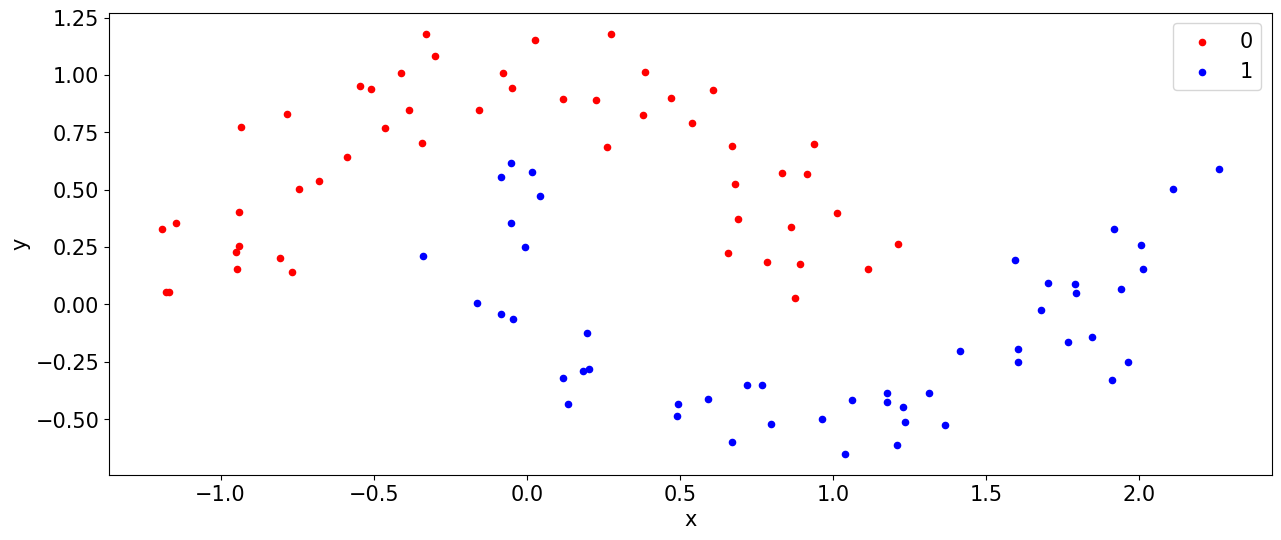

In [127]:
# scatter plot, dots colored by class value
df = DataFrame(dict(x=X[:,0], y=X[:,1], label=y))
colors = {0:'red', 1:'blue', 2:'green'}
fig, ax = pyplot.subplots()
grouped = df.groupby('label')
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
pyplot.show()

In [128]:
np.set_printoptions(linewidth=220, precision=2)
print(X.T)

[[ 0.12  1.31 -0.05 -0.34  0.59  0.96  0.91  0.66 -0.93  0.69 -0.46  1.94  1.23 -0.16  0.2   1.7   0.23 -0.77  0.8   0.13  0.38  0.61 -0.95  1.6  -0.05  2.11  1.21  1.42 -0.05 -0.94  0.39  0.47 -0.3  -1.17 -0.38  1.18
   0.49 -0.78  1.96 -0.94  0.04  0.89 -1.18  0.49  1.01 -0.54 -0.51  0.86  1.6  -0.74  1.68  1.79  1.18 -0.16  0.12  0.03 -0.81  2.26  0.2  -0.08 -0.34  1.79  1.59  2.01  0.77  0.94  1.85  0.72  1.24 -0.08  1.06  0.87
   0.78  0.18  1.04 -0.41  0.67  0.67  2.01  0.54 -0.59 -0.    1.91  1.12 -0.04  1.37  1.92  0.28  1.77 -0.33  0.26 -0.68  0.83  0.02  1.21  0.68 -0.08 -1.19 -0.94 -1.15]
 [ 0.9  -0.39  0.35  0.7  -0.41 -0.5   0.57  0.22  0.77  0.37  0.77  0.07 -0.45  0.   -0.12  0.09  0.89  0.14 -0.52 -0.43  0.83  0.93  0.23 -0.25  0.94  0.5  -0.61 -0.2   0.62  0.26  1.01  0.9   1.08  0.05  0.85 -0.39
  -0.43  0.83 -0.25  0.4   0.47  0.17  0.05 -0.49  0.4   0.95  0.94  0.34 -0.2   0.5  -0.03  0.05 -0.43  0.85 -0.32  1.15  0.2   0.59 -0.28  1.01  0.21  0.09  0.2   0.15 -0.35

In [129]:
print(y)

[0 1 1 0 1 1 0 0 0 0 0 1 1 1 1 1 0 0 1 1 0 0 0 1 0 1 1 1 1 0 0 0 0 0 0 1 1 0 1 0 1 0 0 1 0 0 0 0 1 0 1 1 1 0 1 0 0 1 1 0 1 1 1 1 1 0 1 1 1 1 1 0 0 1 1 0 0 1 1 0 0 1 1 0 1 1 1 0 1 0 0 0 0 1 0 0 1 0 0 0]


# ML ex2data1

In [130]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

In [131]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##### ex2data1, data2
https://drive.google.com/file/d/176uBDnnuoyLQuqR2oeWC3BkBL023puwQ/view?usp=sharing

https://drive.google.com/file/d/1EJf9oTrbjW-jE6oJyrfA1ukuQU0nyxbw/view?usp=sharing

In [132]:
import gdown
import pandas as pd

gdown.download(id='176uBDnnuoyLQuqR2oeWC3BkBL023puwQ', output='ex2data1.txt', quiet=False)

data = pd.read_csv('ex2data1.txt', sep=',',
                   names=['Exam 1 Score', 'Exam 2 Score', 'Result'], header=None)
data


Downloading...
From: https://drive.google.com/uc?id=176uBDnnuoyLQuqR2oeWC3BkBL023puwQ
To: /content/ex2data1.txt
100%|██████████| 3.77k/3.77k [00:00<00:00, 5.63MB/s]


,Exam 1 Score,Exam 2 Score,Result
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1
...,...,...,...
95,83.489163,48.380286,1
96,42.261701,87.103851,1
97,99.315009,68.775409,1
98,55.340018,64.931938,1


In [133]:
data

,Exam 1 Score,Exam 2 Score,Result
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1
...,...,...,...
95,83.489163,48.380286,1
96,42.261701,87.103851,1
97,99.315009,68.775409,1
98,55.340018,64.931938,1


In [134]:
import seaborn as sns

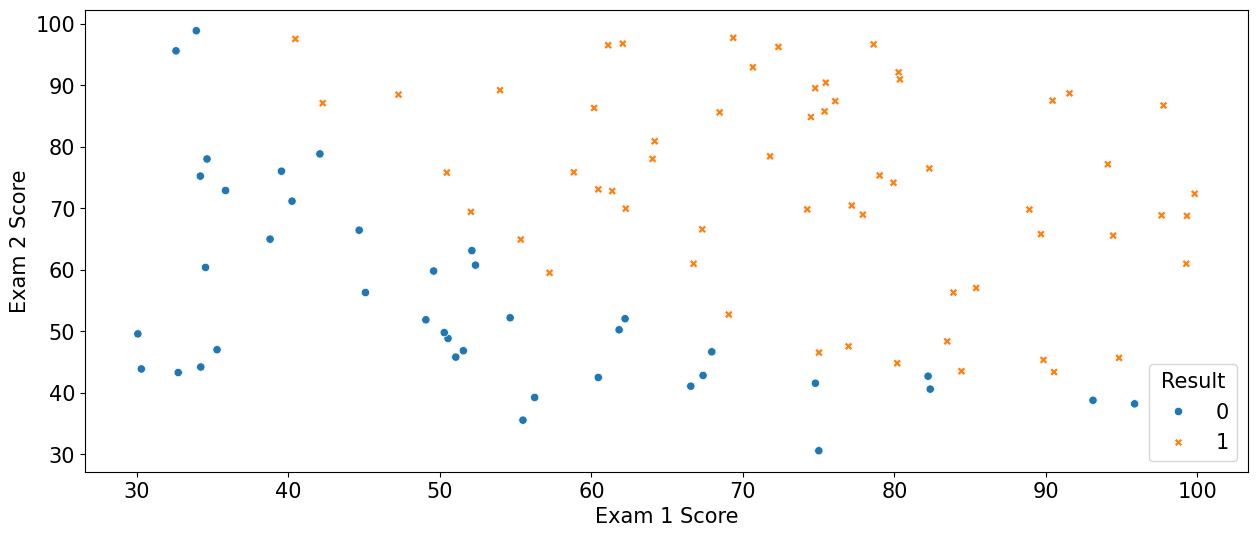

In [135]:
g =sns.scatterplot(x = 'Exam 1 Score', y = 'Exam 2 Score', hue = 'Result', data = data, style = 'Result')